<a href="https://colab.research.google.com/github/christinafan-cell/MSSP607/blob/main/Assignments/Week_8/Week_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/christinafan-cell/MSSP607/blob/main/Assignments/Week_8/Week_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 8: Internet Sales Forecast

**Student:** Christina Fan

## 1. Configure Notebook to connect to GitHub

Run all cells from top to bottom in Google Colab. The notebook and data must be in the same GitHub repository. Expected notebook location: `Assignments/Week_8/Week_8.ipynb`; dataset: `data/InternetSales.csv`.

In [1]:
# Connect to GitHub before loading repository data.
from pathlib import Path
from getpass import getpass
import os
import subprocess
import base64

owner = 'christinafan-cell'
repository = 'MSSP607'
repo_url = f'https://github.com/{owner}/{repository}.git'
repo_path = Path('/content') / repository

if not (repo_path / '.git').is_dir():
    if repo_path.exists():
        raise RuntimeError(
            f'{repo_path} exists but is not a Git repository. '
            'Inspect or rename that folder before running again.'
        )

    # Try public access first; capture output to avoid a long traceback.
    result = subprocess.run(
        ['git', 'clone', repo_url, str(repo_path)],
        capture_output=True, text=True,
        env={**os.environ, 'GIT_TERMINAL_PROMPT': '0'}
    )

    if result.returncode != 0:
        # Retrieve the class-template secret, or ask for a hidden token.
        try:
            from google.colab import userdata
            github_token = userdata.get('Git_Key')
        except Exception:
            github_token = None
        if not github_token:
            github_token = getpass('Enter your GitHub token (not your password): ').strip()
        if not github_token:
            raise RuntimeError('A token is required to retry private repository access.')

        # Pass authentication through a temporary environment variable.
        # The token is not included in the URL or saved in Git configuration.
        authorization = base64.b64encode(
            f'x-access-token:{github_token}'.encode()
        ).decode()
        git_env = {
            **os.environ,
            'GIT_TERMINAL_PROMPT': '0',
            'GIT_CONFIG_COUNT': '1',
            'GIT_CONFIG_KEY_0': 'http.https://github.com/.extraheader',
            'GIT_CONFIG_VALUE_0': f'Authorization: Basic {authorization}'
        }
        result = subprocess.run(
            ['git', 'clone', repo_url, str(repo_path)],
            capture_output=True, text=True, env=git_env
        )
        del github_token, authorization, git_env
        if result.returncode != 0:
            del result
            raise RuntimeError(
                'GitHub connection failed. Check the repository name, your access, '
                'and token expiration / Contents read permission. '
                'Network problems can also prevent cloning.'
            )
    del result
else:
    print('Repository already exists. Using the existing local copy.')

os.chdir(repo_path)
print('Current directory:', os.getcwd())
print('Files in repository:')
for item in sorted(repo_path.rglob('*')):
    if item.is_file() and '.git' not in item.parts:
        print(item.relative_to(repo_path))


Current directory: /content/MSSP607
Files in repository:
Adding_File_Structure.py
Assignment_Template.ipynb
Assignments/.gitkeep
Assignments/Week_1/.gitkeep
Assignments/Week_1/Week1_Introduction_To_Data_Analysis_(2).ipynb
Assignments/Week_10/Week_10_AI_Review_of_Week9_Christina_Fan.ipynb
Assignments/Week_2/.gitkeep
Assignments/Week_2/Week2_Assignment (1).ipynb
Assignments/Week_3/.gitkeep
Assignments/Week_3/Week3_Collatz.ipynb
Assignments/Week_4/.gitkeep
Assignments/Week_4/Week_4.ipynb
Assignments/Week_5/.gitkeep
Assignments/Week_6/.gitkeep
Assignments/Week_6/Week_6_(1).ipynb
Assignments/Week_7/.gitkeep
Assignments/Week_7/Week_7_(1).ipynb
Assignments/Week_7/Week_7_yearly_sales_Christina Fan.pdf
Assignments/Week_8/.gitkeep
Assignments/Week_8/Week_8.ipynb
Assignments/Week_9/Week_9.ipynb
Assignments/case study/.gitkeep
Assignments/case study/case study1/.gitkeep
Assignments/case study/case study1/Assignment1_Christina_Fan_.docx
Assignments/case study/case study1/Assignment_1_PythonCode(2).

## 2. Import Python libraries used in the assignment


In [2]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt
from sklearn.linear_model import LinearRegression
from scipy import stats
from io import StringIO
import itertools
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from IPython.display import display

%matplotlib inline
pd.set_eng_float_format(accuracy=3, use_eng_prefix=True)
pd.set_option('display.float_format', lambda x: '%.2f' % x)


## 3. Code Block: Load data from the repository

The dataset must be stored in `data/InternetSales.csv` inside the repository. No manual upload is needed.


In [3]:
# Load the dataset from the connected GitHub repository.
data_path = repo_path / "data" / "InternetSales.csv"
if not data_path.is_file():
    raise FileNotFoundError(f"Dataset not found: {data_path}. Check its name and location in GitHub.")

df = pd.read_csv(data_path, encoding="latin1", low_memory=False)
df.head()


,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.15,1912.15,3399.99,272.00,85.00,NaN,NaN,1/19/2011,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.62,1265.62,2319.99,185.60,58.00,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.22,8.22,21.98,1.76,0.55,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.94,1481.94,2384.07,190.73,59.60,NaN,NaN,5/3/2013,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.84,10.84,28.99,2.32,0.72,NaN,NaN,5/3/2013,5/15/2013,5/10/2013


## 4. Check and prepare the data



In [4]:
df.columns = df.columns.str.strip()
print(df.columns.tolist())


['ID', 'CustomerKey', 'GeographyKey', 'City', 'CountryRegionCode', 'EnglishCountryRegionName', 'CustomerAlternateKey', 'Title', 'FirstName', 'MiddleName', 'LastName', 'NameStyle', 'BirthDate', 'MaritalStatus', 'Suffix', 'Gender', 'EmailAddress', 'YearlyIncome', 'TotalChildren', 'NumberChildrenAtHome', 'EnglishEducation', 'SpanishEducation', 'FrenchEducation', 'EnglishOccupation', 'SpanishOccupation', 'FrenchOccupation', 'HouseOwnerFlag', 'NumberCarsOwned', 'AddressLine1', 'AddressLine2', 'Phone', 'DateFirstPurchase', 'CommuteDistance', 'ProductKey', 'EnglishProductName', 'OrderDateKey', 'DueDateKey', 'ShipDateKey', 'CustomerKey.1', 'PromotionKey', 'CurrencyKey', 'SalesTerritoryKey', 'SalesOrderNumber', 'SalesOrderLineNumber', 'RevisionNumber', 'OrderQuantity', 'UnitPrice', 'ExtendedAmount', 'UnitPriceDiscountPct', 'DiscountAmount', 'ProductStandardCost', 'TotalProductCost', 'SalesAmount', 'TaxAmt', 'Freight', 'CarrierTrackingNumber', 'CustomerPONumber', 'OrderDate', 'DueDate', 'ShipDat

In [5]:
data = df[["OrderDate", "EnglishProductName", "SalesAmount"]].copy()
data.columns = ["Date", "Product", "Sales"]

data["Date"] = pd.to_datetime(data["Date"], errors="coerce")
data["Sales"] = pd.to_numeric(data["Sales"], errors="coerce")

print(data.isna().sum())
data = data.dropna()

data.head()

Date       0
Product    0
Sales      0
dtype: int64


,Date,Product,Sales
0,2011-01-19,"Mountain-100 Silver, 38",3399.99
1,2013-01-18,"Mountain-200 Silver, 38",2319.99
2,2013-01-18,Fender Set - Mountain,21.98
3,2013-05-03,"Touring-1000 Blue, 46",2384.07
4,2013-05-03,Touring Tire,28.99


## 5. Identify the product with the most sales


In [6]:
product_summary = (
    data.groupby("Product")["Sales"]
    .agg(["sum", "mean", "median", "count"])
    .sort_values("sum", ascending=False)
)

display(product_summary.head(10).round(2))

top_product = product_summary.index[0]
print("Product with the most historical sales:", top_product)
print("Expected future leader if historical product rankings continue:", top_product)


,sum,mean,median,count
Product,,,,
"Mountain-200 Black, 46",1373469.55,2215.27,2294.99,620
"Mountain-200 Black, 42",1363142.09,2220.10,2294.99,614
"Mountain-200 Silver, 38",1339462.79,2247.42,2319.99,596
"Mountain-200 Silver, 46",1301100.10,2243.28,2319.99,580
"Mountain-200 Black, 38",1294866.14,2224.86,2294.99,582
"Mountain-200 Silver, 42",1257434.57,2245.42,2319.99,560
"Road-150 Red, 48",1205876.99,3578.27,3578.27,337
"Road-150 Red, 62",1202298.72,3578.27,3578.27,336
"Road-150 Red, 52",1080637.54,3578.27,3578.27,302


Product with the most historical sales: Mountain-200 Black, 46
Expected future leader if historical product rankings continue: Mountain-200 Black, 46


## 6. Create monthly sales totals

,Sales
count,38.00
mean,772596.77
std,472165.18
min,43421.04
25%,488474.12
50%,599915.03
75%,998939.55
max,1874360.29


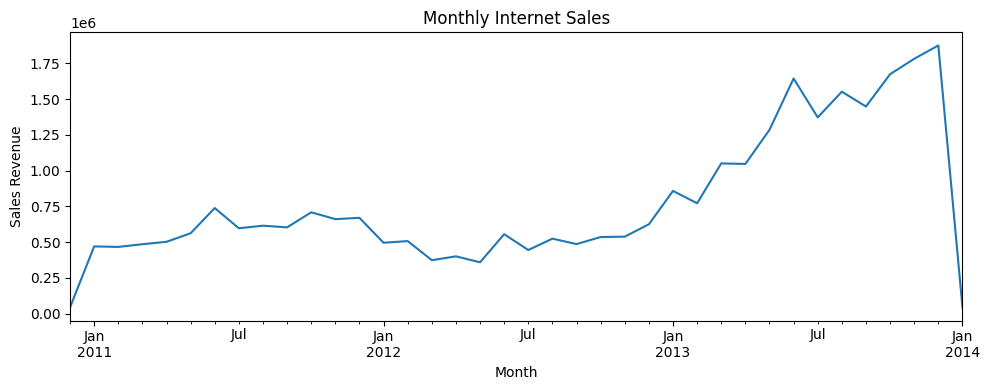

In [7]:
monthly_sales = (
    data.set_index("Date")["Sales"]
    .resample("MS")
    .sum(min_count=1)
)

assert monthly_sales.notna().all(), "Investigate missing months before forecasting."

display(monthly_sales.describe())

monthly_sales.plot(figsize=(10, 4), title="Monthly Internet Sales")
plt.xlabel("Month")
plt.ylabel("Sales Revenue")
plt.tight_layout()
plt.show()


## 7. Forecast the next five years

In [8]:
assert len(monthly_sales) >= 24, "At least 24 months of data are required."

model = ExponentialSmoothing(
    monthly_sales,
    trend="add",
    damped_trend=True,
    seasonal="add",
    seasonal_periods=12
).fit()

forecast = model.forecast(60).clip(lower=0)

forecast_table = pd.DataFrame({
    "Month": forecast.index,
    "Forecast Sales": forecast.values,
    "Forecast Year": np.repeat(range(1, 6), 12)
})

annual_forecast = forecast_table.groupby("Forecast Year").agg(
    Start_Month=("Month", "min"),
    End_Month=("Month", "max"),
    Total_Sales=("Forecast Sales", "sum")
)

display(annual_forecast.round(2))


,Start_Month,End_Month,Total_Sales
Forecast Year,,,
1,2014-02-01,2015-01-01,8653554.43
2,2015-02-01,2016-01-01,6234836.72
3,2016-02-01,2017-01-01,6068623.70
4,2017-02-01,2018-01-01,6057201.63
5,2018-02-01,2019-01-01,6056416.71


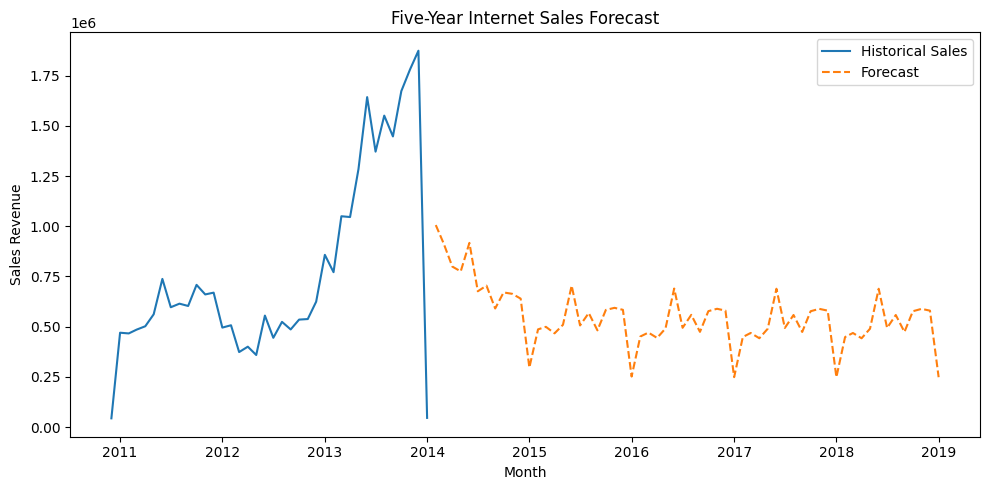

In [9]:
plt.figure(figsize=(10, 5))

plt.plot(monthly_sales, label="Historical Sales")
plt.plot(forecast, label="Forecast", linestyle="--")

plt.title("Five-Year Internet Sales Forecast")
plt.xlabel("Month")
plt.ylabel("Sales Revenue")
plt.legend()
plt.tight_layout()
plt.show()

## 8. Summarize the results

In [10]:
print("Historical sales leader:", top_product)
print(f"Historical revenue: ${product_summary.iloc[0]['sum']:,.2f}")
print(f"Total five-year forecast revenue: ${forecast.sum():,.2f}")
print("Future product leadership assumes historical rankings continue.")
print("Forecasts assume historical patterns continue.")
print("This fictitious dataset is for demonstration only.")

Historical sales leader: Mountain-200 Black, 46
Historical revenue: $1,373,469.55
Total five-year forecast revenue: $33,070,633.20
Future product leadership assumes historical rankings continue.
Forecasts assume historical patterns continue.
This fictitious dataset is for demonstration only.
